In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import ipywidgets as widgets
from IPython.display import display
from scipy.spatial import cKDTree # Optimized import


# Import TDA utilities
from ripser import Rips
from tadasets import torus, sphere
from persim.landscapes import PersLandscapeExact
from persim.landscapes import plot_landscape_simple
from persim.landscapes import PersistenceLandscaper
from persim import plot_diagrams

# Import Scikit-Learn tools
from sklearn.decomposition import PCA
from sklearn import svm
from sklearn import metrics
from sklearn.model_selection import train_test_split

rips = Rips(maxdim=2)
def savePic( filename ):
    # Ensure the output directory exists
    output_dir = os.path.join(os.getcwd(), 'Picture')
    os.makedirs(output_dir, exist_ok=True)
    
    # Save to the "Picture" folder
    filepath = os.path.join(output_dir, filename)
    # print(filepath)
    plt.savefig(filepath, dpi=300, bbox_inches='tight')

Rips(maxdim=2, thresh=inf, coeff=2, do_cocycles=False, n_perm = None, verbose=True)


# Torus point cloud

2.977245717235327


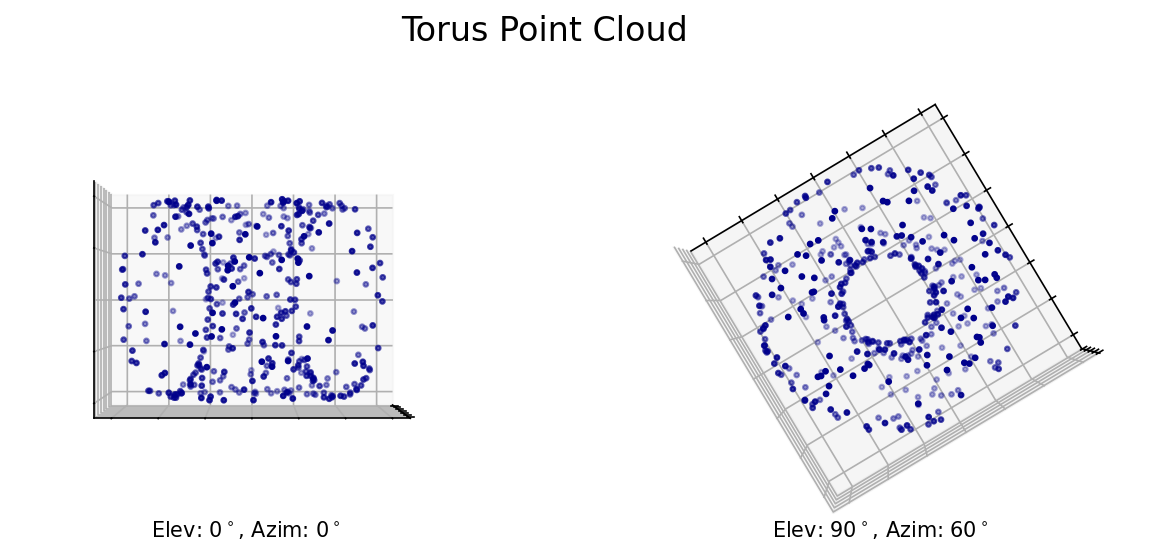

In [2]:
data_torus = torus(n=400, c=2, a=1)
fig = plt.figure(figsize=(10,10), dpi=150)
fig.set_size_inches(10, 4)
print(np.max(data_torus))
elev, azim = 0, 0
ax1 = fig.add_subplot(1,2,1, projection="3d")
ax1.scatter(data_torus[:,0], data_torus[:,1], data_torus[:,2], marker=".", c="darkblue",)
ax1.view_init(elev=elev, azim=azim)
ax1.set_xticklabels([])
ax1.set_yticklabels([])
ax1.set_zticklabels([])
ax1.grid(True)
ax1.text2D(0.5, 0, fr"Elev: ${elev}^\circ$, Azim: ${azim}^\circ$", transform=ax1.transAxes, ha='center')

elev, azim = 90, 60
ax2 = fig.add_subplot(1,2,2, projection="3d")
ax2.scatter(data_torus[:,0], data_torus[:,1], data_torus[:,2], marker=".", c='darkblue')
ax2.view_init(elev=elev, azim=azim)
ax2.set_xticklabels([])
ax2.set_yticklabels([])
ax2.set_zticklabels([])
ax2.grid(True)
ax2.text2D(0.5, 0, rf"Elev: ${elev}^\circ$, Azim: ${azim}^\circ$", transform=ax2.transAxes, ha='center')

# elev, azim = 90, 180
# ax3 = fig.add_subplot(1,3,3, projection="3d")
# ax3.scatter(data_torus[:,0], data_torus[:,1], data_torus[:,2], edgecolors='black', c='skyblue')
# ax3.view_init(elev=elev, azim=azim)
# ax3.set_xticklabels([])
# ax3.set_yticklabels([])
# ax3.set_zticklabels([])
# ax3.grid(True)
# ax3.text2D(0.5, -0.15, rf"Elev: ${elev}^\circ$, Azim: ${azim}^\circ$", transform=ax3.transAxes, ha='center')
# ax2.set_title("Torus Point Cloud", loc='center')
fig.suptitle("Torus Point Cloud", fontsize=16)


plt.show()

#Initial Simplicial Complexes

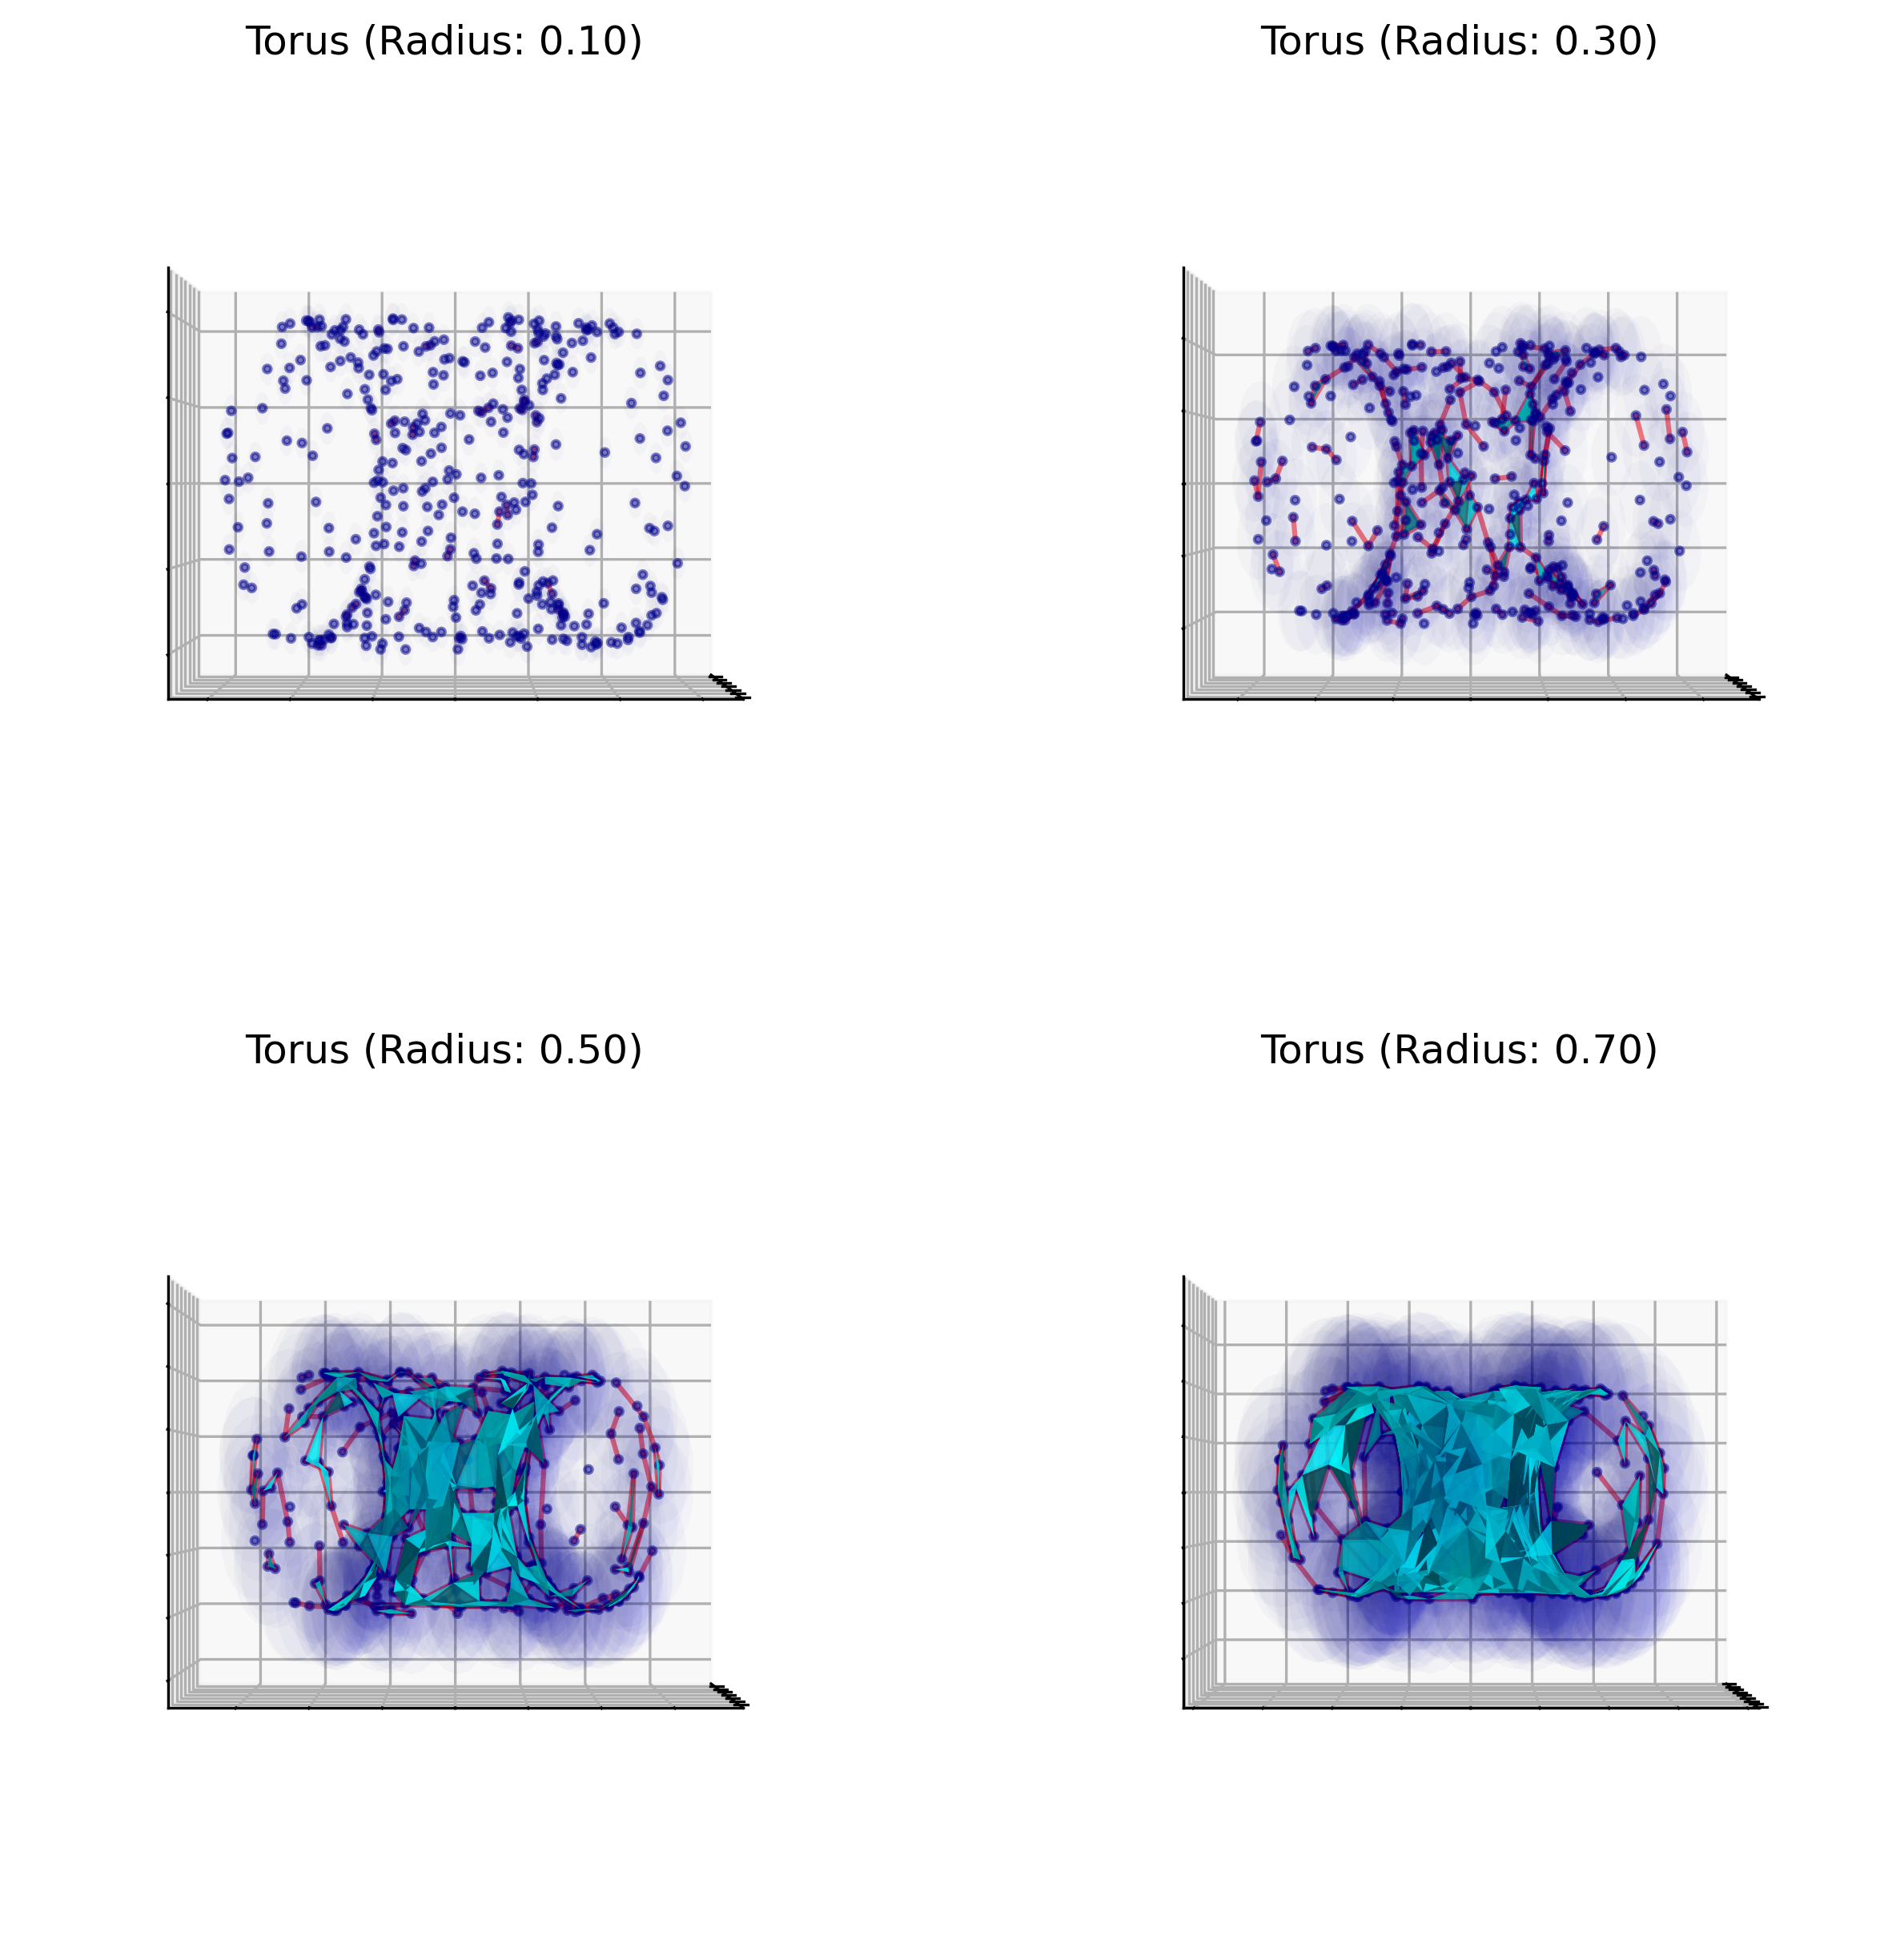

In [3]:
x_noisy = data_torus[:,0]
y_noisy = data_torus[:,1]
z_noisy = data_torus[:,2]
n_points = len(data_torus) # Use len(data_torus) to match the actual data size

# --- 3. Optimized Connection Function (using cKDTree) ---
def connect_points_by_radius(x, y, z, connection_radius):
    points = np.column_stack((x, y, z))
    tree = cKDTree(points)
    pairs = tree.query_pairs(connection_radius)
    connections = list(pairs)
    return connections

# --- 3.1 Optimized Triangle Finding Function ---
def find_triangles_from_connections(connections, n_points):
    adjacency_list = {i: set() for i in range(n_points)}
    for p1, p2 in connections:
        adjacency_list[p1].add(p2)
        adjacency_list[p2].add(p1)

    unique_triangles = set()
    for u, v in connections:
        common_neighbors = adjacency_list[u].intersection(adjacency_list[v])
        for w in common_neighbors:
            triangle = tuple(sorted((u, v, w)))
            unique_triangles.add(triangle)
    return sorted(list(unique_triangles))

# --- Pre-generate a base sphere mesh for plotting (low resolution for performance) ---
phi, theta = np.mgrid[0:np.pi:10j, 0:2*np.pi:10j] # Reduced resolution
x_base_sphere = np.sin(phi) * np.cos(theta)
y_base_sphere = np.sin(phi) * np.sin(theta)
z_base_sphere = np.cos(phi)

# --- 4. Define Interactive Visualization Function ---
def update_plot_with_radius(connection_radius_val, elev, azim, fig, place):
    # plt.close('all') # REMOVED: This was closing the figure prematurely

    connections = connect_points_by_radius(x_noisy, y_noisy, z_noisy, connection_radius_val)
    triangles = find_triangles_from_connections(connections, n_points)

    ax = fig.add_subplot(2,2,place, projection='3d')

    # Set viewpoint
    ax.view_init(elev=elev, azim=azim)

    # Plot spheres at noisy points, scaled by connection_radius_val
    if n_points > 0: # Ensure there are points to plot
        # Create a dummy legend entry for spheres
        ax.plot_surface(x_base_sphere * connection_radius_val + x_noisy[0],
                        y_base_sphere * connection_radius_val + y_noisy[0],
                        z_base_sphere * connection_radius_val + z_noisy[0],
                        color='blue', alpha=0.01, linewidth=0)
        for idx in range(n_points):
            # Scale and translate the base sphere mesh for each point
            sphere_x = x_base_sphere * connection_radius_val + x_noisy[idx]
            sphere_y = y_base_sphere * connection_radius_val + y_noisy[idx]
            sphere_z = z_base_sphere * connection_radius_val + z_noisy[idx]
            ax.plot_surface(sphere_x, sphere_y, sphere_z, color='blue', alpha=0.01, linewidth=0)

    # Add a scatter plot for individual markers on top of the spheres
    ax.scatter(x_noisy, y_noisy, z_noisy, c='darkblue', alpha=0.5, label='Points', marker=".") # Adjusted s to 1

    # Plot connections
    if connections:
        ax.plot([], [], [], color='red', linewidth=1.5, alpha=0.5, label='Connections')
        for i, j in connections:
            x_pair = [x_noisy[i], x_noisy[j]]
            y_pair = [y_noisy[i], y_noisy[j]]
            z_pair = [z_noisy[i], z_noisy[j]]
            ax.plot(x_pair, y_pair, z_pair, color='red', linewidth=1.5, alpha=0.5)

    # Plot triangles as 3D surfaces
    if triangles:
        ax.plot_trisurf(x_noisy, y_noisy, z_noisy, triangles=np.array(triangles), color='cyan', alpha=0.8, label='Triangles')
    else:
        ax.plot([], [], [], color='cyan', alpha=0.4, label='Triangles') # Dummy for legend


    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_zticklabels([])
    ax.set_title(f'Torus (Radius: {connection_radius_val:.2f})')

fig = plt.figure(figsize=(10,10), dpi=300)

update_plot_with_radius(0.1, 0, 0, fig, 1)
update_plot_with_radius(0.3, 0, 0, fig, 2)

update_plot_with_radius(0.5, 0, 0, fig, 3)
update_plot_with_radius(0.7, 0, 0, fig, 4)
savePic("2by4 Torus diff radii")
plt.show()

#Focus Grid

(400, 3)
(6, 3)


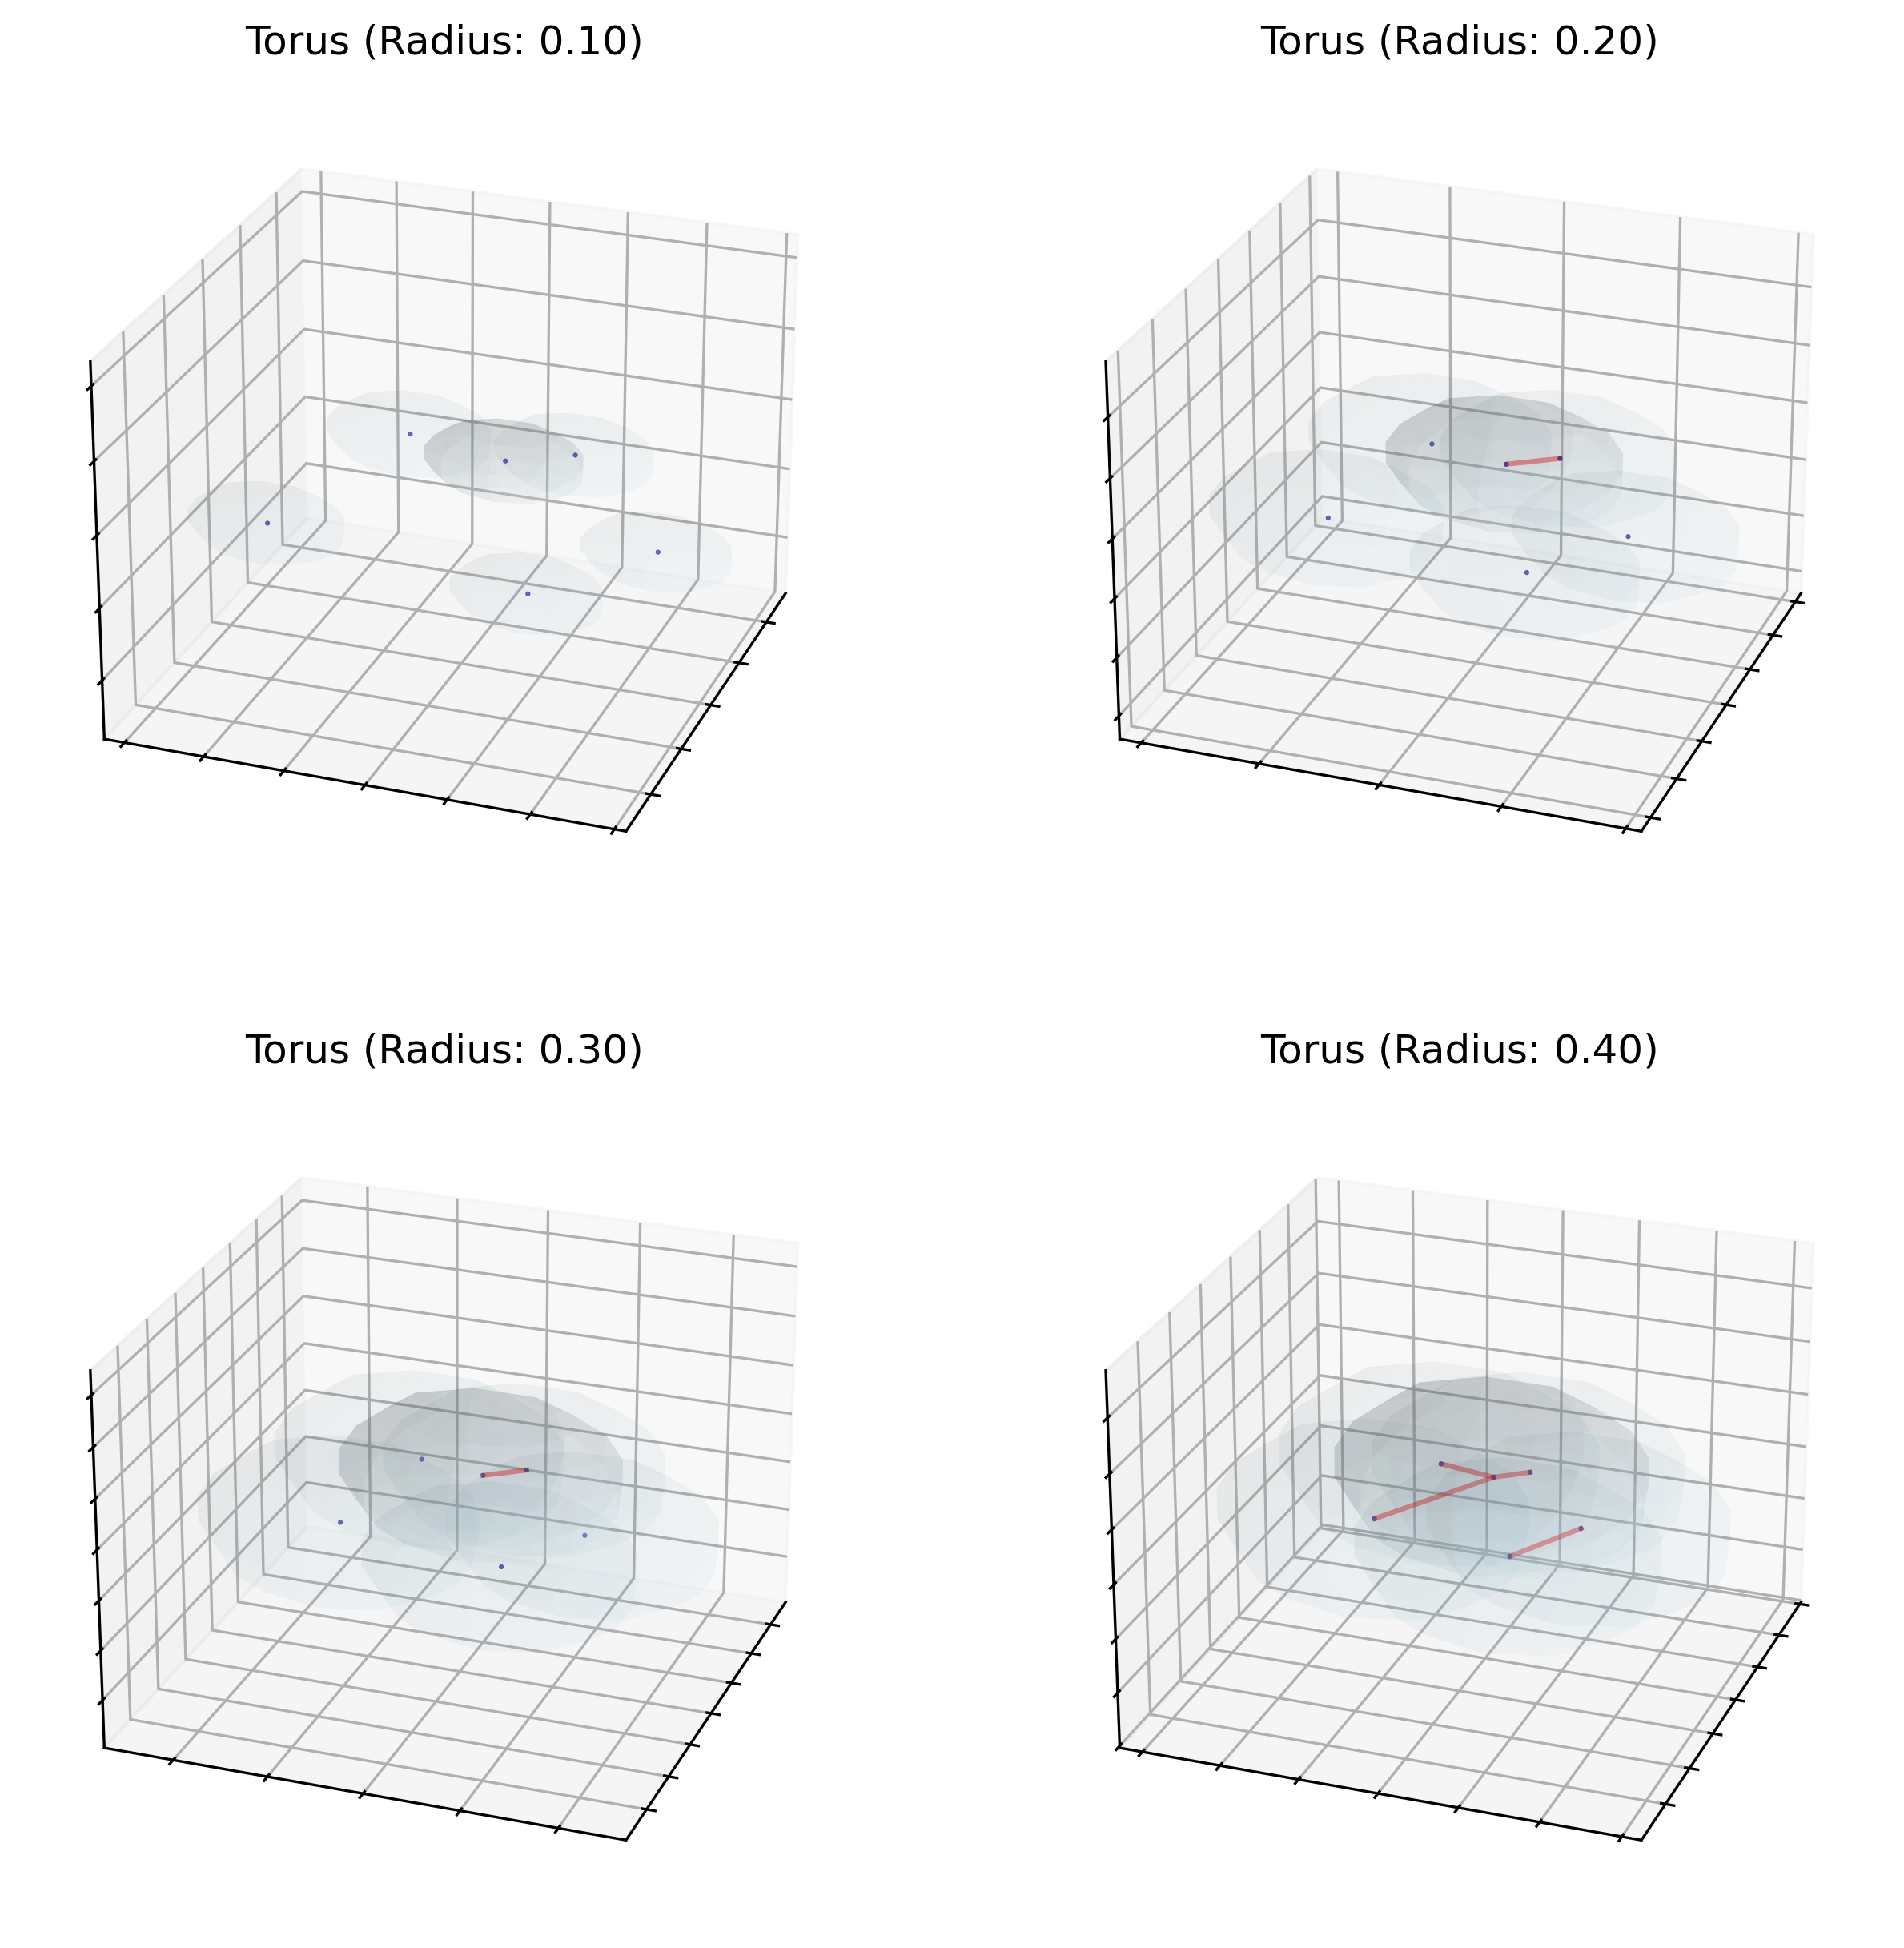

In [4]:
# Filter data_torus to keep points within the [0, 1] cube
filtered_data_torus = data_torus[
    (data_torus[:, 0] >= 0) & (data_torus[:, 0] <= 1) &
    (data_torus[:, 1] >= 0) & (data_torus[:, 1] <= 1) &
    (data_torus[:, 2] >= 0) & (data_torus[:, 2] <= 1)
]
print(data_torus.shape)
print(filtered_data_torus.shape)

x_noisy = filtered_data_torus[:,0]
y_noisy = filtered_data_torus[:,1]
z_noisy = filtered_data_torus[:,2]
n_points = len(filtered_data_torus) # Use len(data_torus) to match the actual data size

# --- 3. Optimized Connection Function (using cKDTree) ---
def connect_points_by_radius(x, y, z, connection_radius):
    points = np.column_stack((x, y, z))
    tree = cKDTree(points)
    pairs = tree.query_pairs(connection_radius)
    connections = list(pairs)
    return connections

# --- 3.1 Optimized Triangle Finding Function ---
def find_triangles_from_connections(connections, n_points):
    adjacency_list = {i: set() for i in range(n_points)}
    for p1, p2 in connections:
        adjacency_list[p1].add(p2)
        adjacency_list[p2].add(p1)

    unique_triangles = set()
    for u, v in connections:
        common_neighbors = adjacency_list[u].intersection(adjacency_list[v])
        for w in common_neighbors:
            triangle = tuple(sorted((u, v, w)))
            unique_triangles.add(triangle)
    return sorted(list(unique_triangles))

# --- Pre-generate a base sphere mesh for plotting (low resolution for performance) ---
phi, theta = np.mgrid[0:np.pi:10j, 0:2*np.pi:10j] # Reduced resolution
x_base_sphere = np.sin(phi) * np.cos(theta)
y_base_sphere = np.sin(phi) * np.sin(theta)
z_base_sphere = np.cos(phi)

# --- 4. Define Interactive Visualization Function ---
def update_plot_with_radius(connection_radius_val, elev, azim, fig, graph):
    # plt.close('all') # REMOVED: This was closing the figure prematurely

    connections = connect_points_by_radius(x_noisy, y_noisy, z_noisy, connection_radius_val)
    triangles = find_triangles_from_connections(connections, n_points)

    ax = fig.add_subplot(2,2,graph, projection='3d')

    # Set viewpoint
    ax.view_init(elev=elev, azim=azim)

    # Plot spheres at noisy points, scaled by connection_radius_val
    if n_points > 0: # Ensure there are points to plot
        # Create a dummy legend entry for spheres
        ax.plot_surface(x_base_sphere * connection_radius_val + x_noisy[0],
                        y_base_sphere * connection_radius_val + y_noisy[0],
                        z_base_sphere * connection_radius_val + z_noisy[0],
                        color='white', alpha=0.1, linewidth=0)
        for idx in range(n_points):
            # Scale and translate the base sphere mesh for each point
            sphere_x = x_base_sphere * connection_radius_val + x_noisy[idx]
            sphere_y = y_base_sphere * connection_radius_val + y_noisy[idx]
            sphere_z = z_base_sphere * connection_radius_val + z_noisy[idx]
            ax.plot_surface(sphere_x, sphere_y, sphere_z, color='skyblue', alpha=0.03, linewidth=0)

    # Add a scatter plot for individual markers on top of the spheres
    ax.scatter(x_noisy, y_noisy, z_noisy, c='darkblue', s=1, alpha=0.6, label='Points', marker=".") # Adjusted s to 1

    # Plot connections
    if connections:
        ax.plot([], [], [], color='red', linewidth=1.5, alpha=0.5, label='Connections')
        for i, j in connections:
            x_pair = [x_noisy[i], x_noisy[j]]
            y_pair = [y_noisy[i], y_noisy[j]]
            z_pair = [z_noisy[i], z_noisy[j]]
            ax.plot(x_pair, y_pair, z_pair, color='red', linewidth=1.5, alpha=0.5)

    # Plot triangles as 3D surfaces
    if triangles:
        ax.plot_trisurf(x_noisy, y_noisy, z_noisy, triangles=np.array(triangles), color='cyan', alpha=0.8, label='Triangles')
    else:
        ax.plot([], [], [], color='cyan', alpha=0.4, label='Triangles') # Dummy for legend


    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_zticklabels([])
    ax.set_title(f'Torus (Radius: {connection_radius_val:.2f})')

fig = plt.figure(figsize=(10,10), dpi=300)

update_plot_with_radius(0.1, 25, 20, fig, 1)
update_plot_with_radius(0.2, 25, 20, fig, 2)
update_plot_with_radius(0.3, 25, 20, fig, 3)
update_plot_with_radius(0.4, 25, 20, fig, 4)

savePic("2by2 zoom in simplicial_complex_torus")
plt.show()


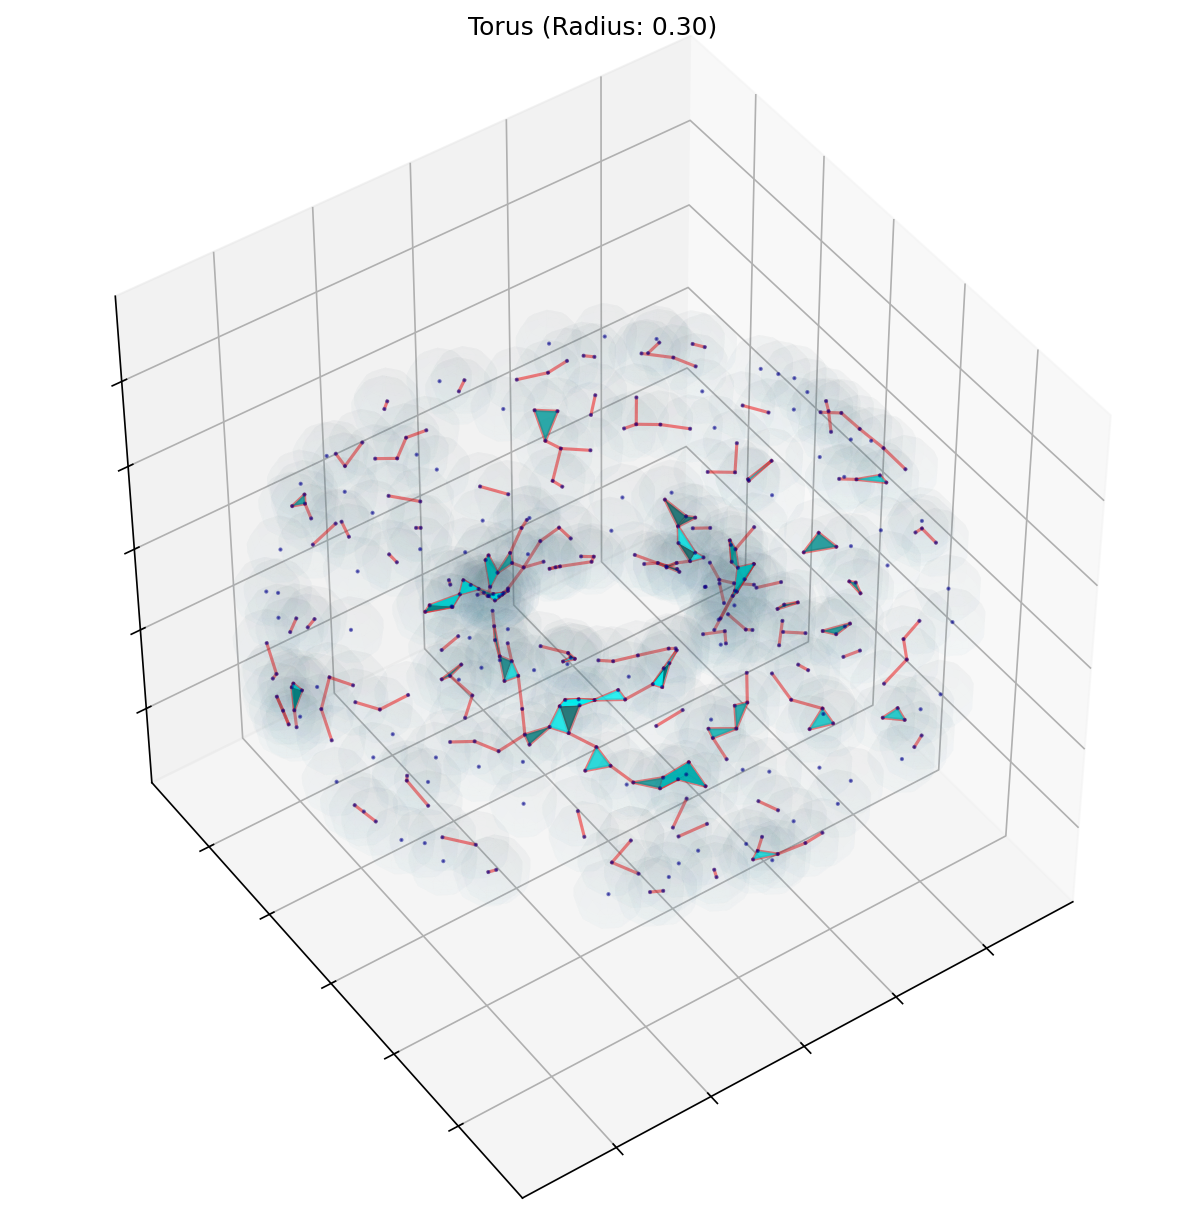

In [5]:
x_noisy = data_torus[:,0]
y_noisy = data_torus[:,1]
z_noisy = data_torus[:,2]
n_points = len(data_torus) # Use len(data_torus) to match the actual data size

# --- 3. Optimized Connection Function (using cKDTree) ---
def connect_points_by_radius(x, y, z, connection_radius):
    points = np.column_stack((x, y, z))
    tree = cKDTree(points)
    pairs = tree.query_pairs(connection_radius)
    connections = list(pairs)
    return connections

# --- 3.1 Optimized Triangle Finding Function ---
def find_triangles_from_connections(connections, n_points):
    adjacency_list = {i: set() for i in range(n_points)}
    for p1, p2 in connections:
        adjacency_list[p1].add(p2)
        adjacency_list[p2].add(p1)

    unique_triangles = set()
    for u, v in connections:
        common_neighbors = adjacency_list[u].intersection(adjacency_list[v])
        for w in common_neighbors:
            triangle = tuple(sorted((u, v, w)))
            unique_triangles.add(triangle)
    return sorted(list(unique_triangles))

# --- Pre-generate a base sphere mesh for plotting (low resolution for performance) ---
phi, theta = np.mgrid[0:np.pi:10j, 0:2*np.pi:10j] # Reduced resolution
x_base_sphere = np.sin(phi) * np.cos(theta)
y_base_sphere = np.sin(phi) * np.sin(theta)
z_base_sphere = np.cos(phi)

# --- 4. Define Interactive Visualization Function ---
def update_plot_with_radius(connection_radius_val, elev, azim, fig, ax):
    # plt.close('all') # REMOVED: This was closing the figure prematurely

    connections = connect_points_by_radius(x_noisy, y_noisy, z_noisy, connection_radius_val)
    triangles = find_triangles_from_connections(connections, n_points)

    # Set viewpoint
    ax.view_init(elev=elev, azim=azim)

    # Set equal aspect ratio for 3D plot
    ax.set_box_aspect([1, 1, 1])

    # Plot spheres at noisy points, scaled by connection_radius_val
    if n_points > 0: # Ensure there are points to plot
        # Create a dummy legend entry for spheres
        ax.plot_surface(x_base_sphere * connection_radius_val + x_noisy[0],
                        y_base_sphere * connection_radius_val + y_noisy[0],
                        z_base_sphere * connection_radius_val + z_noisy[0],
                        color='white', alpha=0.02, linewidth=0)
        for idx in range(n_points):
            # Scale and translate the base sphere mesh for each point
            sphere_x = x_base_sphere * connection_radius_val + x_noisy[idx]
            sphere_y = y_base_sphere * connection_radius_val + y_noisy[idx]
            sphere_z = z_base_sphere * connection_radius_val + z_noisy[idx]
            ax.plot_surface(sphere_x, sphere_y, sphere_z, color='skyblue', alpha=0.02, linewidth=0)

    # Add a scatter plot for individual markers on top of the spheres
    ax.scatter(x_noisy, y_noisy, z_noisy, c='darkblue', s=1, alpha=0.5, label='Points') # Adjusted s to 1

    # Plot connections
    if connections:
        ax.plot([], [], [], color='red', linewidth=1.5, alpha=0.5, label='Connections')
        for i, j in connections:
            x_pair = [x_noisy[i], x_noisy[j]]
            y_pair = [y_noisy[i], y_noisy[j]]
            z_pair = [z_noisy[i], z_noisy[j]]
            ax.plot(x_pair, y_pair, z_pair, color='red', linewidth=1.5, alpha=0.5)

    # Plot triangles as 3D surfaces
    if triangles:
        ax.plot_trisurf(x_noisy, y_noisy, z_noisy, triangles=np.array(triangles), color='cyan', alpha=0.8, label='Triangles')
    else:
        ax.plot([], [], [], color='cyan', alpha=0.4, label='Triangles') # Dummy for legend


    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_zticklabels([])


fig = plt.figure(figsize=(10,10), dpi=150)
ax = fig.add_subplot(1,1,1, projection='3d')

all_coords = data_torus.flatten()
min_overall = np.min(all_coords)
max_overall = np.max(all_coords)
ax.set_xlim([min_overall, max_overall])
ax.set_ylim([min_overall, max_overall])
ax.set_zlim([min_overall, max_overall])
ax.set_title(f'Torus (Radius: {.3:.2f})')
update_plot_with_radius(0.3, 45, 55, fig, ax)

savePic("simplical_complex_whole_torus")
plt.show()

In [6]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import ipywidgets as widgets
from IPython.display import display
from scipy.spatial import cKDTree

# --- Optimized Connection Function (using cKDTree) ---
def connect_points_by_radius(x, y, z, connection_radius):
    points = np.column_stack((x, y, z))
    tree = cKDTree(points)
    pairs = tree.query_pairs(connection_radius)
    connections = list(pairs)
    return connections

# --- Optimized Triangle Finding Function ---
def find_triangles_from_connections(connections, n_points):
    adjacency_list = {i: set() for i in range(n_points)}
    for p1, p2 in connections:
        adjacency_list[p1].add(p2)
        adjacency_list[p2].add(p1)

    unique_triangles = set()
    for u, v in connections:
        common_neighbors = adjacency_list[u].intersection(adjacency_list[v])
        for w in common_neighbors:
            triangle = tuple(sorted((u, v, w)))
            unique_triangles.add(triangle)
    return sorted(list(unique_triangles))

# --- Pre-generate a base sphere mesh for plotting (low resolution for performance) ---
phi_base, theta_base = np.mgrid[0:np.pi:10j, 0:2*np.pi:10j] # Reduced resolution
x_base_sphere_mesh = np.sin(phi_base) * np.cos(theta_base)
y_base_sphere_mesh = np.sin(phi_base) * np.sin(theta_base)
z_base_sphere_mesh = np.cos(phi_base)

# Define the interactive plotting function
def interactive_plot_combined(elev, azim, connection_radius_val):
    fig = plt.figure(figsize=(12, 10), dpi=100)

    # --- Main Plot (background) ---
    ax_main = fig.add_subplot(111, projection='3d') # Main subplot

    # Plot Cube Perimeter on main_ax
    vertices = np.array([
        [0, 0, 0], [1, 0, 0], [1, 1, 0], [0, 1, 0],
        [0, 0, 1], [1, 0, 1], [1, 1, 1], [0, 1, 1]
    ])
    edges = [
        [0, 1], [1, 2], [2, 3], [3, 0],
        [4, 5], [5, 6], [6, 7], [7, 4],
        [0, 4], [1, 5], [2, 6], [3, 7]
    ]
    for edge in edges:
        ax_main.plot3D(vertices[edge, 0], vertices[edge, 1], vertices[edge, 2], 'purple', linewidth=2)

    # --- Data for Main Plot (full data_torus) ---
    x_noisy_main = data_torus[:, 0]
    y_noisy_main = data_torus[:, 1]
    z_noisy_main = data_torus[:, 2]
    n_points_main = len(data_torus)

    if n_points_main > 0:
        connections_main = connect_points_by_radius(x_noisy_main, y_noisy_main, z_noisy_main, connection_radius_val)
        triangles_main = find_triangles_from_connections(connections_main, n_points_main)

        ax_main.scatter(x_noisy_main, y_noisy_main, z_noisy_main, c='darkblue', s=1, alpha=0.5, label='Points')
        if connections_main:
            for i, j in connections_main:
                x_pair = [x_noisy_main[i], x_noisy_main[j]]
                y_pair = [y_noisy_main[i], y_noisy_main[j]]
                z_pair = [z_noisy_main[i], z_noisy_main[j]]
                ax_main.plot(x_pair, y_pair, z_pair, color='red', linewidth=1.5, alpha=0.5)
        if triangles_main:
            ax_main.plot_trisurf(x_noisy_main, y_noisy_main, z_noisy_main, triangles=np.array(triangles_main), color='cyan', alpha=0.8)

    # Main plot settings
    ax_main.set_box_aspect([1, 1, 1]) # Equal aspect ratio
    ax_main.view_init(elev=elev, azim=azim)
    # ax_main.set_xlabel('X')
    # ax_main.set_ylabel('Y')
    # ax_main.set_zlabel('Z')
    ax_main.set_title(f'Torus in Cube (Radius: {connection_radius_val:.2f}) - Main View')

    # Set global limits for all axes in the main plot
    all_coords = data_torus.flatten()
    min_overall = np.min(all_coords)
    max_overall = np.max(all_coords)
    ax_main.set_xlim([min_overall, max_overall])
    ax_main.set_ylim([min_overall, max_overall])
    ax_main.set_zlim([min_overall, max_overall])

    ax_main.tick_params(axis='x', colors="white")
    ax_main.tick_params(axis='y', colors="white")
    ax_main.tick_params(axis='z', colors="white")


    # --- Inset Plot (upper right corner) ---
    # [left, bottom, width, height] in figure coordinates (0-1)
    ax_inset = fig.add_axes([0.05, 0.65, 0.25, 0.25], projection='3d')
    ax_inset.set_facecolor((0, 0, 0, 0)) # Set transparent facecolor explicitly

    # --- Data for Inset Plot (filtered_data_torus) ---
    filtered_data_torus = data_torus[
        (data_torus[:, 0] > 0) & (data_torus[:, 0] < 1) &
        (data_torus[:, 1] > 0) & (data_torus[:, 1] < 1) &
        (data_torus[:, 2] > 0) & (data_torus[:, 2] < 1)
    ]

    x_noisy_filtered = filtered_data_torus[:, 0]
    y_noisy_filtered = filtered_data_torus[:, 1]
    z_noisy_filtered = filtered_data_torus[:, 2]
    n_points_filtered = len(filtered_data_torus)

    if n_points_filtered > 0:
        connections_filtered = connect_points_by_radius(x_noisy_filtered, y_noisy_filtered, z_noisy_filtered, connection_radius_val)
        triangles_filtered = find_triangles_from_connections(connections_filtered, n_points_filtered)

        # Plot only filtered torus data on inset_ax (without cube perimeter)
        ax_inset.scatter(x_noisy_filtered, y_noisy_filtered, z_noisy_filtered, c='darkblue', s=1, alpha=0.5)
        if connections_filtered: # Reusing connections from main plot
            for i, j in connections_filtered:
                x_pair = [x_noisy_filtered[i], x_noisy_filtered[j]]
                y_pair = [y_noisy_filtered[i], y_noisy_filtered[j]]
                z_pair = [z_noisy_filtered[i], z_noisy_filtered[j]]
                ax_inset.plot(x_pair, y_pair, z_pair, color='red', linewidth=1.5, alpha=0.5)
        if triangles_filtered: # Reusing triangles from main plot
            ax_inset.plot_trisurf(x_noisy_filtered, y_noisy_filtered, z_noisy_filtered, triangles=np.array(triangles_filtered), color='cyan', alpha=0.8)

    # Inset plot settings
    ax_inset.set_box_aspect([1, 1, 1]) # Equal aspect ratio
    ax_inset.view_init(elev=elev, azim=azim)
    ax_inset.set_title('Zoom In', fontsize=8) # Smaller title


    ax_inset.grid(True, color="black", linestyle='--', linewidth=1)
    ax_inset.tick_params(axis='x', colors="white", labelsize=2) # Set x-axis tick color to black
    ax_inset.tick_params(axis='y', colors="white", labelsize=2) # Set y-axis tick color to black
    ax_inset.tick_params(axis='z', colors="white", labelsize=2) # Set z-axis tick color to black

    savePic("focus region Torus ")
    
    plt.show()


# Create sliders
elev_slider = widgets.IntSlider(min=-90, max=90, step=5, description='Elevation:', value=0)
azim_slider = widgets.IntSlider(min=0, max=360, step=5, description='Azimuth:', value=0)
connection_radius_slider = widgets.FloatSlider(min=0.0, max=1.0, step=0.05, description='Radius:', value=0.3, readout=True, readout_format='.2f')


# Display the interactive plot
interactive_output = widgets.interactive(interactive_plot_combined,
                                         elev=elev_slider,
                                         azim=azim_slider,
                                         connection_radius_val=connection_radius_slider)
display(interactive_output)



interactive(children=(IntSlider(value=0, description='Elevation:', max=90, min=-90, step=5), IntSlider(value=0…

In [7]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
import gudhi as gd

# 1. Load coordinates from CSV
points = data_torus

print(f"Number of points: {len(points)}")
print(f"Point data min: {np.min(points):.2f}, max: {np.max(points):.2f}")

# 2. Generate Simplicial Complex (Alpha Complex)
alpha_complex = gd.AlphaComplex(points=points)
simplex_tree = alpha_complex.create_simplex_tree()

# Extract triangles (2-simplices) for visualization
all_2_simplices = [s for s in simplex_tree.get_skeleton(2) if len(s[0]) == 3]

print(f"Number of all 2-simplices found: {len(all_2_simplices)}")

max_triangle_alpha = 0
if all_2_simplices:
    max_triangle_alpha = max(s[1] for s in all_2_simplices)
    print(f"Maximum alpha value for any triangle in the complex: {max_triangle_alpha:.2f}")
else:
    print("No 2-simplices (triangles) found in the simplex tree.")

alpha_value = 0.1 # Use this to ensure all found triangles are included

# Filter triangles based on alpha_value
filtered_triangles_list = [s[0] for s in all_2_simplices if s[1] <= alpha_value]

print(f"Number of filtered triangles: {len(filtered_triangles_list)}")

if filtered_triangles_list:
    triangles = np.array(filtered_triangles_list, dtype=int)
else:
    triangles = np.empty((0, 3), dtype=int)
    print(f"No triangles found for alpha_value <= {alpha_value}. Plotly Mesh3d will be empty.")

# 3. Visualize with Plotly
fig = go.Figure()

# Add a scatter plot of the points themselves to verify if points are rendered
fig.add_trace(go.Scatter3d(
    x=points[:, 0],
    y=points[:, 1],
    z=points[:, 2],
    mode='markers',
    marker=dict(size=4, color='blue', opacity=0.8), # Increased marker size
    name='Torus Points'
))

# Add the Mesh3d trace if triangles were found
if len(triangles) > 0:
    fig.add_trace(go.Mesh3d(
        x=points[:, 0],
        y=points[:, 1],
        z=points[:, 2],
        i=triangles[:, 0],
        j=triangles[:, 1],
        k=triangles[:, 2],
        opacity=0.8, # Increased opacity for better visibility
        color='lightcoral', # Changed color to be distinct from points
        name='Alpha Complex Triangles'
    ))
else:
    print("Mesh3d trace not added as no triangles were found.")

fig.update_layout(title="3D Simplicial Complex from Torus Points")

import plotly.io as pio
pio.renderers.default = 'iframe' # Changed renderer to 'colab'

fig.show()

Number of points: 400
Point data min: -2.97, max: 2.98
Number of all 2-simplices found: 6759
Maximum alpha value for any triangle in the complex: 1020390055.06
Number of filtered triangles: 512


In [8]:
import pandas as pd
import numpy as np
import gudhi as gd
import plotly.graph_objects as go
from ipywidgets import interact, FloatSlider

# 1. Load coordinates
points = data_torus

print(f"Number of points: {len(points)}")

# 2. Pre-compute Simplicial Complex (Alpha Complex)
# We do this outside the function for better performance
alpha_complex = gd.AlphaComplex(points=points, )
simplex_tree = alpha_complex.create_simplex_tree()

# Pre-extract all 2-simplices and their filtration values (alpha^2)
all_2_simplices = [(s[0], s[1]) for s in simplex_tree.get_skeleton(2) if len(s[0]) == 3]

# Define the update function for the slider
def update_plot(alpha_value):
    # Filter triangles based on alpha_value
    filtered_triangles = [s[0] for s in all_2_simplices if s[1] <= alpha_value]

    if filtered_triangles:
        triangles = np.array(filtered_triangles, dtype=int)
    else:
        triangles = np.empty((0, 3), dtype=int)

    # 3. Visualize with Plotly
    fig = go.Figure(data=[
        go.Mesh3d(
            x=points[:, 0], y=points[:, 1], z=points[:, 2],
            i=triangles[:, 0] if len(triangles) > 0 else [],
            j=triangles[:, 1] if len(triangles) > 0 else [],
            k=triangles[:, 2] if len(triangles) > 0 else [],
            opacity=0.5,
            color='cyan'
        ),
        # Add scatter points so the nodes remain visible even without triangles
        go.Scatter3d(
            x=points[:, 0], y=points[:, 1], z=points[:, 2],
            mode='markers',
            marker=dict(size=2, color='black', opacity=0.8)
        )
    ])

    fig.update_layout(
        title=f"3D Simplicial Complex (Alpha: {alpha_value})",
        scene=dict(xaxis_title='X', yaxis_title='Y', zaxis_title='Z'),
        margin=dict(l=0, r=0, b=0, t=40), width= 800, height=600
    )
    # output_dir = os.path.join(os.getcwd(), 'Pictures')
    # os.makedirs(output_dir, exist_ok=True)
    
    # filepath = os.path.join(output_dir, 'my_plot.png')
    # fig.write_image(filepath, width=800, height=600, scale=2)
    fig.show()

# Determine a reasonable range for the slider
max_alpha = max([s[1] for s in all_2_simplices]) if all_2_simplices else 1000
print(max_alpha)
# Create the interactive slider
interact(update_plot, alpha_value=FloatSlider(
    value=0,
    min=0,
    max=1,
    step=1/40,
    description='Alpha Value:'
));


Number of points: 400
1020390055.0648377


interactive(children=(FloatSlider(value=0.0, description='Alpha Value:', max=1.0, step=0.025), Output()), _dom…